# GTSRB exploratory data analysis

German Traffic Sign Recognition Benchmark — class balance, image geometry, appearance variability, and confusable pairs.

Data via `torchvision.datasets.GTSRB`. Class names from the community-standard `signnames.csv` mapping (Udacity CarND / Kaggle).

## 0. Setup & load data

In [ ]:
from __future__ import annotations

from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from torchvision.datasets import GTSRB

plt.rcParams.update(
    {
        "figure.figsize": (12, 4),
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

DATA_ROOT = Path("data")
N_CLASSES = 43

train = GTSRB(root=str(DATA_ROOT), split="train", download=True)
test = GTSRB(root=str(DATA_ROOT), split="test", download=True)

print(f"Train images: {len(train):,}")
print(f"Test images:  {len(test):,}")
print(f"Sample item:  {type(train[0][0]).__name__}, class={train[0][1]}")

In [2]:
# Canonical English names (ClassId 0–42), matching Udacity CarND signnames.csv
SIGN_NAMES = {
    0: "Speed limit (20km/h)",
    1: "Speed limit (30km/h)",
    2: "Speed limit (50km/h)",
    3: "Speed limit (60km/h)",
    4: "Speed limit (70km/h)",
    5: "Speed limit (80km/h)",
    6: "End of speed limit (80km/h)",
    7: "Speed limit (100km/h)",
    8: "Speed limit (120km/h)",
    9: "No passing",
    10: "No passing for vehicles over 3.5 metric tons",
    11: "Right-of-way at the next intersection",
    12: "Priority road",
    13: "Yield",
    14: "Stop",
    15: "No vehicles",
    16: "Vehicles over 3.5 metric tons prohibited",
    17: "No entry",
    18: "General caution",
    19: "Dangerous curve to the left",
    20: "Dangerous curve to the right",
    21: "Double curve",
    22: "Bumpy road",
    23: "Slippery road",
    24: "Road narrows on the right",
    25: "Road work",
    26: "Traffic signals",
    27: "Pedestrians",
    28: "Children crossing",
    29: "Bicycles crossing",
    30: "Beware of ice/snow",
    31: "Wild animals crossing",
    32: "End of all speed and passing limits",
    33: "Turn right ahead",
    34: "Turn left ahead",
    35: "Ahead only",
    36: "Go straight or right",
    37: "Go straight or left",
    38: "Keep right",
    39: "Keep left",
    40: "Roundabout mandatory",
    41: "End of no passing",
    42: "End of no passing by vehicles over 3.5 metric tons",
}

# Informal taxonomy for EDA slicing (not an official GTSRB field)
SIGN_GROUPS = {
    **{i: "Speed" for i in range(0, 9)},
    **{i: "Prohibitory" for i in (9, 10, 15, 16, 17)},
    **{i: "Priority" for i in (11, 12, 13, 14)},
    **{i: "Danger" for i in range(18, 32)},
    **{i: "Other" for i in (32, 41, 42)},
    **{i: "Mandatory" for i in range(33, 41)},
}

signnames = pd.DataFrame(
    {
        "ClassId": list(range(N_CLASSES)),
        "SignName": [SIGN_NAMES[i] for i in range(N_CLASSES)],
        "Group": [SIGN_GROUPS[i] for i in range(N_CLASSES)],
    }
)
signnames

,ClassId,SignName,Group
0,0,Speed limit (20km/h),Speed
1,1,Speed limit (30km/h),Speed
2,2,Speed limit (50km/h),Speed
3,3,Speed limit (60km/h),Speed
4,4,Speed limit (70km/h),Speed
5,5,Speed limit (80km/h),Speed
6,6,End of speed limit (80km/h),Speed
7,7,Speed limit (100km/h),Speed
8,8,Speed limit (120km/h),Speed
9,9,No passing,Prohibitory


## 1. Class counts — by class and by group

Overall accuracy is misleading if a few speed-limit classes dominate. Macro-F1 and per-class recall matter more for safety-critical use.

In [3]:
def class_counts(dataset: GTSRB) -> pd.Series:
    # Prefer labels from _samples to avoid decoding every PPM
    labels = [target for _, target in dataset._samples]
    return pd.Series(Counter(labels)).sort_index().reindex(range(N_CLASSES), fill_value=0)


train_counts = class_counts(train).rename("train")
test_counts = class_counts(test).rename("test")

counts = (
    signnames.set_index("ClassId")
    .join(train_counts)
    .join(test_counts)
    .assign(
        train_pct=lambda d: 100 * d["train"] / d["train"].sum(),
        test_pct=lambda d: 100 * d["test"] / d["test"].sum(),
    )
)

print(
    f"Train total={counts['train'].sum():,}  "
    f"min={counts['train'].min()} ({SIGN_NAMES[int(counts['train'].idxmin())]})  "
    f"max={counts['train'].max()} ({SIGN_NAMES[int(counts['train'].idxmax())]})  "
    f"imbalance ratio={counts['train'].max() / counts['train'].min():.1f}x"
)
counts.sort_values("train", ascending=False).head(10)

Train total=26,640  min=150 (Speed limit (20km/h))  max=1500 (Speed limit (30km/h))  imbalance ratio=10.0x


,SignName,Group,train,test,train_pct,test_pct
ClassId,,,,,,
2,Speed limit (50km/h),Speed,1500,750,5.630631,5.938242
1,Speed limit (30km/h),Speed,1500,720,5.630631,5.700713
13,Yield,Priority,1440,720,5.405405,5.700713
12,Priority road,Priority,1410,690,5.292793,5.463183
38,Keep right,Mandatory,1380,690,5.180180,5.463183
10,No passing for vehicles over 3.5 metric tons,Prohibitory,1350,660,5.067568,5.225653
4,Speed limit (70km/h),Speed,1320,660,4.954955,5.225653
5,Speed limit (80km/h),Speed,1260,630,4.729730,4.988124
25,Road work,Danger,1020,480,3.828829,3.800475


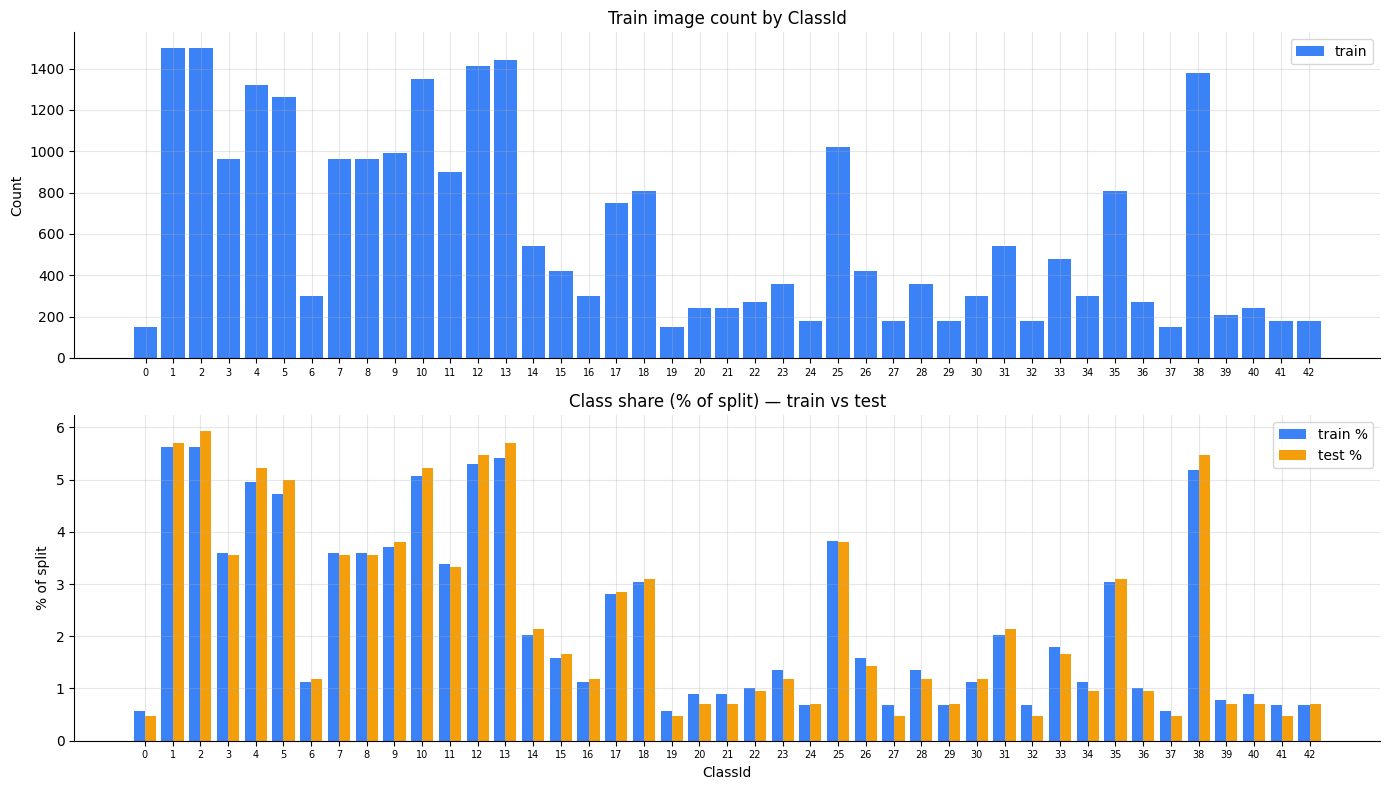

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=False)

x = np.arange(N_CLASSES)
axes[0].bar(x, counts["train"], color="#3b82f6", label="train", width=0.85)
axes[0].set_title("Train image count by ClassId")
axes[0].set_ylabel("Count")
axes[0].set_xticks(x)
axes[0].set_xticklabels(x, fontsize=7)
axes[0].legend()

axes[1].bar(x - 0.2, counts["train_pct"], width=0.4, color="#3b82f6", label="train %")
axes[1].bar(x + 0.2, counts["test_pct"], width=0.4, color="#f59e0b", label="test %")
axes[1].set_title("Class share (% of split) — train vs test")
axes[1].set_xlabel("ClassId")
axes[1].set_ylabel("% of split")
axes[1].set_xticks(x)
axes[1].set_xticklabels(x, fontsize=7)
axes[1].legend()

fig.tight_layout()
plt.show()

The data looks stratified between train and test sets. Speed and priority sign classes capture the majority of samples.  

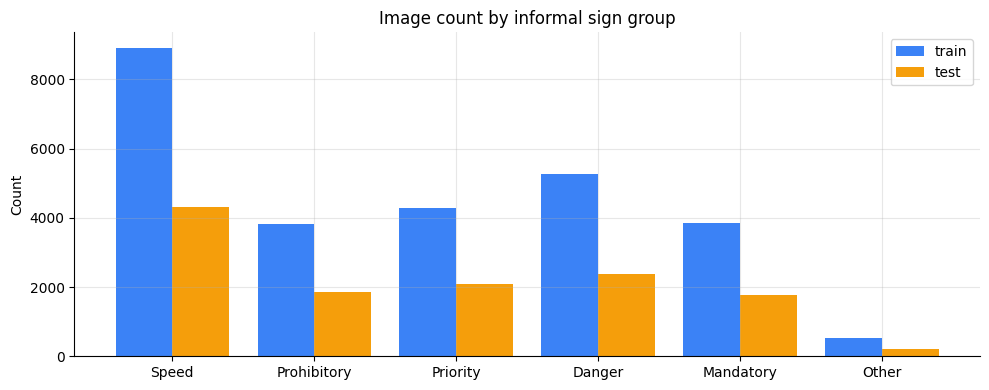

,train,test,n_classes
Group,,,
Speed,8910,4320,9
Prohibitory,3810,1860,5
Priority,4290,2100,4
Danger,5250,2370,14
Mandatory,3840,1770,8
Other,540,210,3


In [5]:
group_order = ["Speed", "Prohibitory", "Priority", "Danger", "Mandatory", "Other"]
group_train = counts.groupby("Group")["train"].sum().reindex(group_order)
group_test = counts.groupby("Group")["test"].sum().reindex(group_order)

fig, ax = plt.subplots(figsize=(10, 4))
idx = np.arange(len(group_order))
ax.bar(idx - 0.2, group_train, width=0.4, color="#3b82f6", label="train")
ax.bar(idx + 0.2, group_test, width=0.4, color="#f59e0b", label="test")
ax.set_xticks(idx)
ax.set_xticklabels(group_order)
ax.set_ylabel("Count")
ax.set_title("Image count by informal sign group")
ax.legend()
fig.tight_layout()
plt.show()

pd.DataFrame({"train": group_train, "test": group_test, "n_classes": counts.groupby("Group").size().reindex(group_order)})

Here the data looks stratified even by EDA group - Speed, Prohibitory, Priority, etc. 

## 2. Size & brightness + sample montage

Variable resolution drives resize/letterbox choices. Brightness spread drives color/brightness augmentation strength.

In [6]:
def collect_geometry_and_brightness(dataset: GTSRB, max_brightness_samples: int | None = None):
    """Widths/heights for all images; mean grayscale brightness on a subsample if capped."""
    widths, heights, labels = [], [], []
    brightness, bright_labels = [], []

    n = len(dataset._samples)
    bright_idx = set(range(n))
    if max_brightness_samples is not None and max_brightness_samples < n:
        rng = np.random.default_rng(0)
        bright_idx = set(rng.choice(n, size=max_brightness_samples, replace=False).tolist())

    for i, (path, target) in enumerate(dataset._samples):
        with Image.open(path) as im:
            w, h = im.size
            widths.append(w)
            heights.append(h)
            labels.append(target)
            if i in bright_idx:
                # Mean luminance proxy without full RGB→LAB conversion
                gray = np.asarray(im.convert("L"), dtype=np.float32)
                brightness.append(float(gray.mean()))
                bright_labels.append(target)

    geo = pd.DataFrame({"width": widths, "height": heights, "ClassId": labels})
    geo["area"] = geo["width"] * geo["height"]
    geo["aspect"] = geo["width"] / geo["height"]
    bright = pd.DataFrame({"brightness": brightness, "ClassId": bright_labels})
    return geo, bright


train_geo, train_bright = collect_geometry_and_brightness(train)
test_geo, test_bright = collect_geometry_and_brightness(test)

print("Train size summary:")
display(train_geo[["width", "height", "area", "aspect"]].describe().round(2))
print("Test size summary:")
display(test_geo[["width", "height", "area", "aspect"]].describe().round(2))

Train size summary:


,width,height,area,aspect
count,26640.00,26640.00,26640.00,26640.00
mean,50.93,50.37,3118.88,1.01
std,24.37,23.16,3684.97,0.07
min,25.00,25.00,625.00,0.37
25%,35.00,35.00,1190.00,0.97
50%,43.00,43.00,1849.00,1.00
75%,58.00,58.00,3364.00,1.04
max,243.00,225.00,54675.00,1.42


Test size summary:


,width,height,area,aspect
count,12630.00,12630.00,12630.00,12630.00
mean,50.51,50.36,3125.01,1.00
std,25.09,23.70,3930.96,0.08
min,25.00,25.00,625.00,0.39
25%,34.00,35.00,1190.00,0.97
50%,43.00,43.00,1845.00,1.00
75%,58.00,57.00,3306.00,1.04
max,266.00,232.00,61712.00,1.44


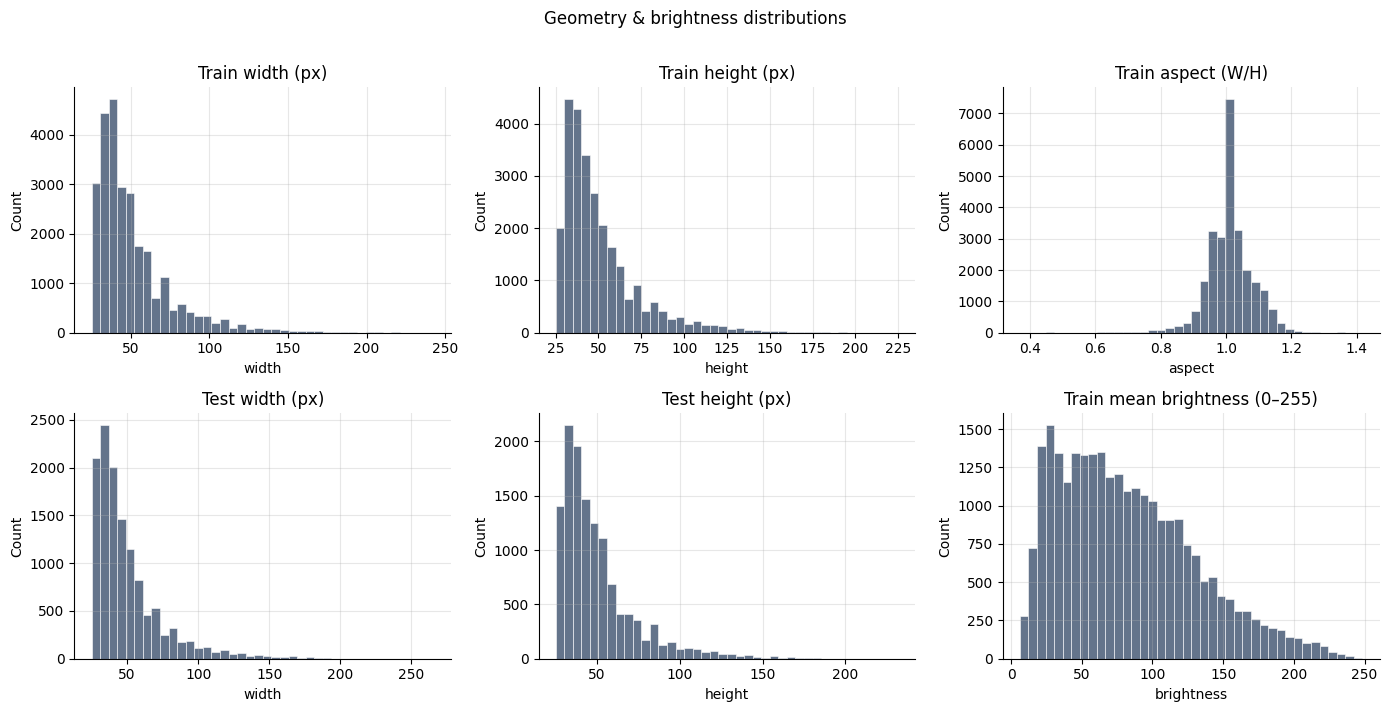

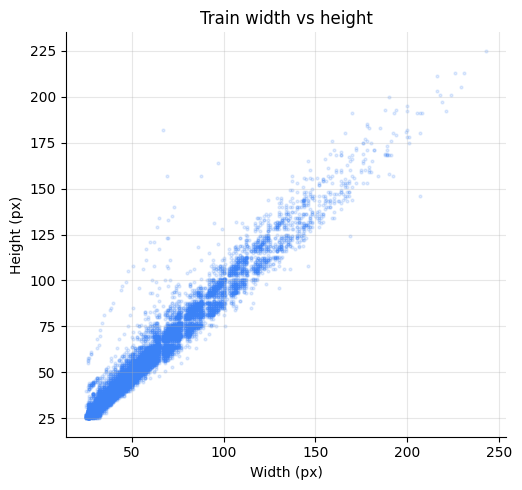

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))

for ax, series, title in [
    (axes[0, 0], train_geo["width"], "Train width (px)"),
    (axes[0, 1], train_geo["height"], "Train height (px)"),
    (axes[0, 2], train_geo["aspect"], "Train aspect (W/H)"),
    (axes[1, 0], test_geo["width"], "Test width (px)"),
    (axes[1, 1], test_geo["height"], "Test height (px)"),
    (axes[1, 2], train_bright["brightness"], "Train mean brightness (0–255)"),
]:
    ax.hist(series, bins=40, color="#64748b", edgecolor="white", linewidth=0.4)
    ax.set_title(title)
    ax.set_xlabel(series.name)
    ax.set_ylabel("Count")

fig.suptitle("Geometry & brightness distributions", y=1.01)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(train_geo["width"], train_geo["height"], s=4, alpha=0.15, c="#3b82f6", rasterized=True)
ax.set_xlabel("Width (px)")
ax.set_ylabel("Height (px)")
ax.set_title("Train width vs height")
ax.set_aspect("equal", adjustable="box")
fig.tight_layout()
plt.show()

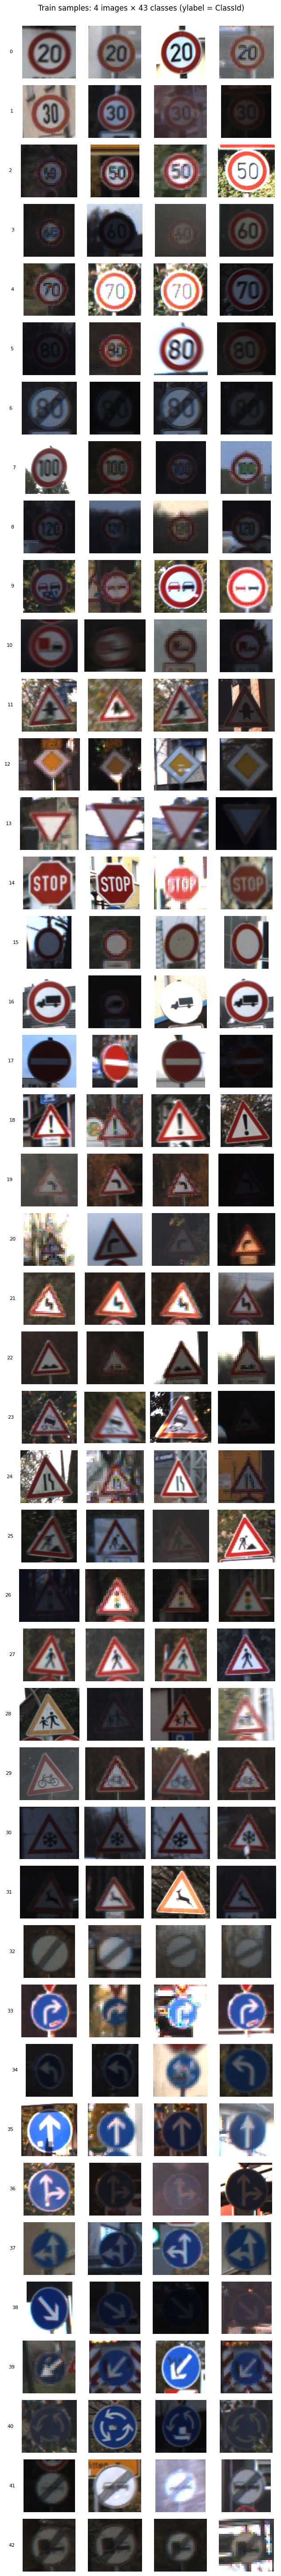

In [8]:
def indices_by_class(dataset: GTSRB) -> dict[int, list[int]]:
    buckets: dict[int, list[int]] = defaultdict(list)
    for i, (_, target) in enumerate(dataset._samples):
        buckets[int(target)].append(i)
    return buckets


def show_montage(
    dataset: GTSRB,
    class_ids: list[int] | None = None,
    n_per_class: int = 4,
    seed: int = 0,
    title: str = "Sample montage",
):
    class_ids = class_ids or list(range(N_CLASSES))
    buckets = indices_by_class(dataset)
    rng = np.random.default_rng(seed)

    n_rows = len(class_ids)
    fig, axes = plt.subplots(n_rows, n_per_class, figsize=(1.6 * n_per_class, 1.35 * n_rows))
    if n_rows == 1:
        axes = np.expand_dims(axes, 0)
    if n_per_class == 1:
        axes = np.expand_dims(axes, 1)

    for r, cid in enumerate(class_ids):
        pool = buckets[cid]
        chosen = rng.choice(pool, size=min(n_per_class, len(pool)), replace=False)
        for c in range(n_per_class):
            ax = axes[r, c]
            ax.set_xticks([])
            ax.set_yticks([])
            for spine in ax.spines.values():
                spine.set_visible(False)
            if c >= len(chosen):
                ax.axis("off")
                continue
            img, _ = dataset[int(chosen[c])]
            ax.imshow(img)
            if c == 0:
                ax.set_ylabel(f"{cid}", rotation=0, labelpad=18, fontsize=8, va="center")

    fig.suptitle(title, y=1.0)
    fig.tight_layout()
    plt.show()


# Full 43-class overview (4 examples each) — long figure, skim for blur / lighting / distance
show_montage(train, n_per_class=4, seed=1, title="Train samples: 4 images × 43 classes (ylabel = ClassId)")

## 3. Confusable pairs — speed limits & left/right mirrors

These are the pairs a confusion matrix usually lights up first.

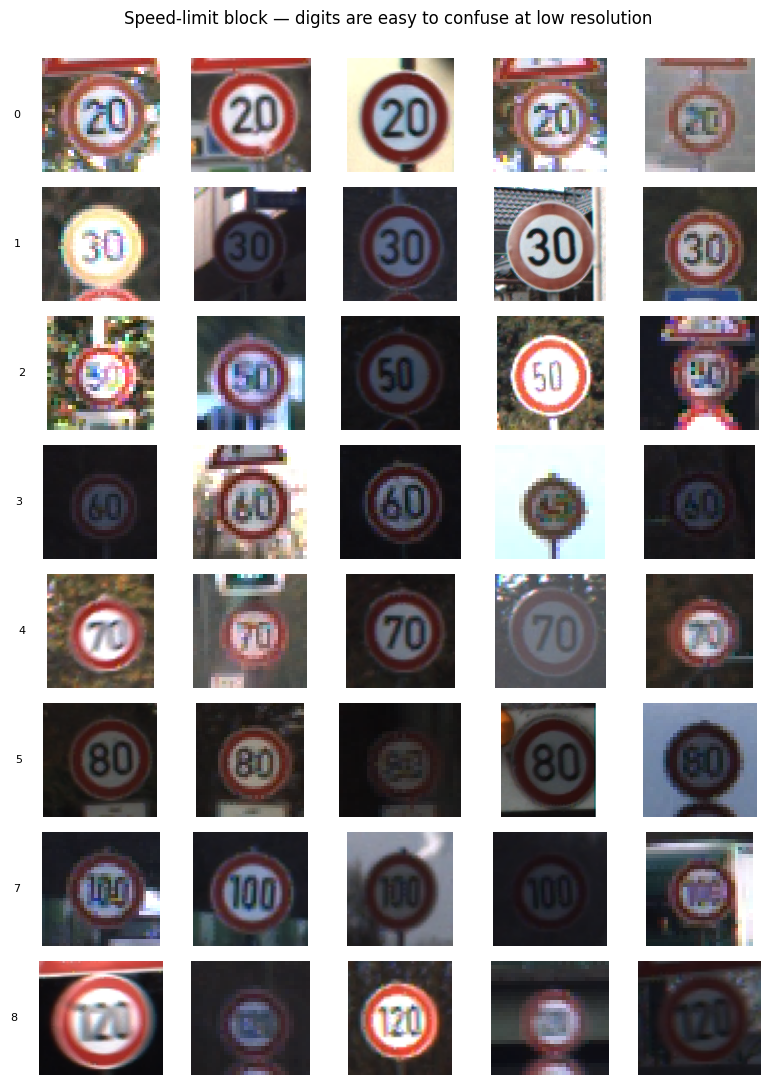

   0: Speed limit (20km/h)  (train n=150)
   1: Speed limit (30km/h)  (train n=1500)
   2: Speed limit (50km/h)  (train n=1500)
   3: Speed limit (60km/h)  (train n=960)
   4: Speed limit (70km/h)  (train n=1320)
   5: Speed limit (80km/h)  (train n=1260)
   7: Speed limit (100km/h)  (train n=960)
   8: Speed limit (120km/h)  (train n=960)


In [9]:
SPEED_LIMIT_IDS = [0, 1, 2, 3, 4, 5, 7, 8]  # active speed limits (exclude "end of 80")

show_montage(
    train,
    class_ids=SPEED_LIMIT_IDS,
    n_per_class=5,
    seed=2,
    title="Speed-limit block — digits are easy to confuse at low resolution",
)

for cid in SPEED_LIMIT_IDS:
    print(f"  {cid:2d}: {SIGN_NAMES[cid]}  (train n={int(counts.loc[cid, 'train'])})")

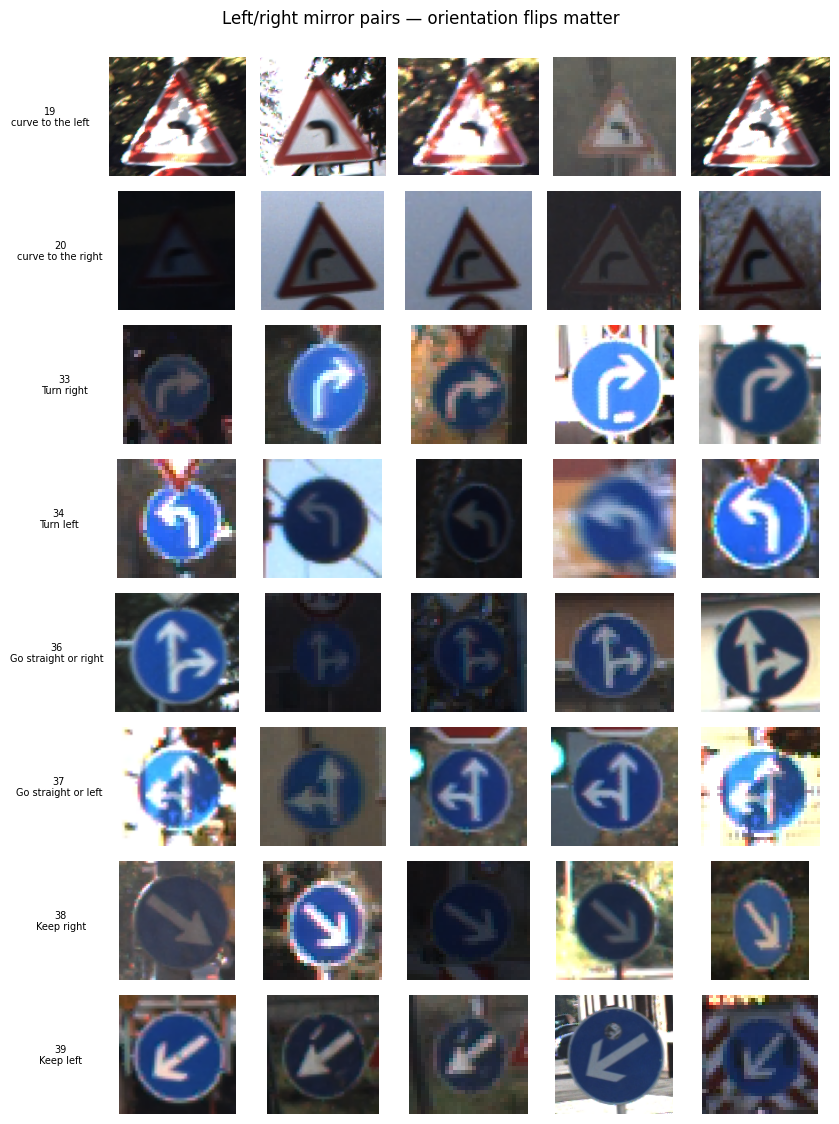

Also watch: active prohibition vs 'end of …' variants
  5 Speed limit (80km/h)
  6 End of speed limit (80km/h)

  9 No passing
  41 End of no passing

  10 No passing for vehicles over 3.5 metric tons
  42 End of no passing by vehicles over 3.5 metric tons



In [10]:
MIRROR_PAIRS = [
    (19, 20),  # dangerous curve L/R
    (33, 34),  # turn ahead L/R
    (36, 37),  # straight or L/R
    (38, 39),  # keep L/R
]


def show_pair_grid(dataset: GTSRB, pairs: list[tuple[int, int]], n: int = 5, seed: int = 3):
    buckets = indices_by_class(dataset)
    rng = np.random.default_rng(seed)
    n_rows = len(pairs) * 2
    fig, axes = plt.subplots(n_rows, n, figsize=(1.7 * n, 1.4 * n_rows))

    row = 0
    for a, b in pairs:
        for cid in (a, b):
            chosen = rng.choice(buckets[cid], size=min(n, len(buckets[cid])), replace=False)
            for c in range(n):
                ax = axes[row, c]
                ax.set_xticks([])
                ax.set_yticks([])
                for spine in ax.spines.values():
                    spine.set_visible(False)
                if c >= len(chosen):
                    ax.axis("off")
                    continue
                img, _ = dataset[int(chosen[c])]
                ax.imshow(img)
                if c == 0:
                    short = SIGN_NAMES[cid].replace("Dangerous ", "").replace(" ahead", "")
                    ax.set_ylabel(f"{cid}\n{short}", fontsize=7, rotation=0, labelpad=42, va="center")
            row += 1

    fig.suptitle("Left/right mirror pairs — orientation flips matter", y=1.0)
    fig.tight_layout()
    plt.show()


show_pair_grid(train, MIRROR_PAIRS, n=5, seed=3)

print("Also watch: active prohibition vs 'end of …' variants")
for a, b in [(5, 6), (9, 41), (10, 42)]:
    print(f"  {a} {SIGN_NAMES[a]}")
    print(f"  {b} {SIGN_NAMES[b]}")
    print()

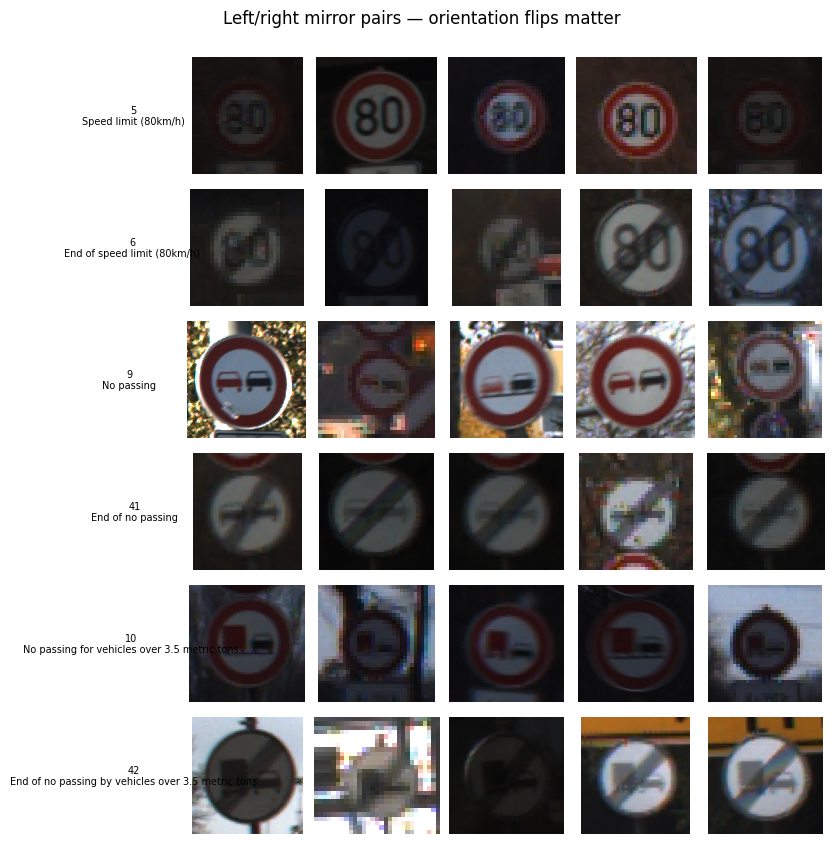

In [11]:
# Side-by-side: prohibition vs end-of-prohibition
END_PAIRS = [(5, 6), (9, 41), (10, 42)]
show_pair_grid(train, END_PAIRS, n=5, seed=4)

## 4. Lock the product problem → primary metric

EDA findings above should feed a **written** modeling contract before training. Pick one primary business problem and freeze the metric that decides model selection.

In [12]:
# Edit this cell to lock the project framing before modeling.
PRODUCT_PROBLEM = "research_benchmark"  # one of the keys below

PROBLEM_CARDS = {
    "adas_safety": {
        "description": "ADAS / AV — safety-critical recognition of cropped signs",
        "primary_metric": "Per-class recall on Stop(14), Yield(13), No entry(17), speed limits; with abstain/calibration",
        "secondary_metrics": ["macro-F1", "ECE", "on-device latency"],
        "modeling_notes": "Class weights or focal loss; reject low-confidence; never select on overall accuracy alone.",
    },
    "driver_alert": {
        "description": "In-cabin alert — reduce missed speed limits without nagging",
        "primary_metric": "False-alert rate per km + precision of alerts",
        "secondary_metrics": ["time-to-detect", "family-level accuracy"],
        "modeling_notes": "Temporal smoothing over tracks; threshold tuned for UX.",
    },
    "map_freshness": {
        "description": "Fleet cameras updating HD-map sign inventory",
        "primary_metric": "Precision of proposed map edits @ location",
        "secondary_metrics": ["rare-class F1", "coverage"],
        "modeling_notes": "Offline OK; multi-view voting; active learning on disagreements.",
    },
    "research_benchmark": {
        "description": "Reproduce / beat GTSRB official test accuracy",
        "primary_metric": "Official test-set top-1 accuracy",
        "secondary_metrics": ["macro-F1", "per-class accuracy", "confusion on speed block"],
        "modeling_notes": "Use torchvision/official split; report mean±std; strong augmentation usually > exotic nets.",
    },
}

card = PROBLEM_CARDS[PRODUCT_PROBLEM]
print("=" * 72)
print("LOCKED PRODUCT PROBLEM:", PRODUCT_PROBLEM)
print(card["description"])
print("-" * 72)
print("PRIMARY METRIC:", card["primary_metric"])
print("Secondary:", "; ".join(card["secondary_metrics"]))
print("Notes:", card["modeling_notes"])
print("=" * 72)

# Quick reminder from EDA numbers
rare = counts.sort_values("train").head(5)[["SignName", "train", "test"]]
print("\nRarest train classes (watch macro-F1 / per-class recall):")
display(rare)

LOCKED PRODUCT PROBLEM: research_benchmark
Reproduce / beat GTSRB official test accuracy
------------------------------------------------------------------------
PRIMARY METRIC: Official test-set top-1 accuracy
Secondary: macro-F1; per-class accuracy; confusion on speed block
Notes: Use torchvision/official split; report mean±std; strong augmentation usually > exotic nets.

Rarest train classes (watch macro-F1 / per-class recall):


,SignName,train,test
ClassId,,,
0,Speed limit (20km/h),150,60
37,Go straight or left,150,60
19,Dangerous curve to the left,150,60
32,End of all speed and passing limits,180,60
29,Bicycles crossing,180,90


### EDA takeaways checklist

- [ ] Noted **imbalance ratio** (max/min train count) and whether class weights are needed
- [ ] Chose input size given **width/height** distribution (common baselines: 32×32 or 48×48)
- [ ] Planned augmentation for **brightness / blur / small signs**
- [ ] Expect confusion on **speed digits** and **L/R mirrors** — inspect those cells first after training
- [ ] Locked **primary metric** in the cell above before hyperparameter search

**Reminder:** GTSRB is cropped *recognition*. Full-frame dashcam products also need a *detector* (e.g. GTSDB).